# 08b — Evaluation as case discovery

This notebook does not train the model or rewrite labels. It compares the promoted full-match candidate with the public reference after the candidate has been generated. The purpose is to identify observable football cases that the pipeline must discover: a delayed dead-ball boundary, a short-touch handoff, a contested contact, or an uncertain missing-ball interval.

The diagrams are evidence for those cases, not extra supervision. They show the candidate prediction, public reference, disagreement boundaries, missing-ball intervals, scenarios, anchors, and match time. The public labels never enter feature construction or the resolver.

## What is measured

| Measure | Why it matters |
|---|---|
| Macro-F1 | Balanced frame quality for H, A and D. |
| Mean Spell-F1 | Whether possession and dead-ball intervals have the right continuity. |
| Transition F1@25 | Whether changes occur close to the reference transition. |

The promoted bounded three-family hybrid ties the forward-settling reference on the public slice: **0.895 macro-F1, 0.640 Spell-F1, 0.486 transition F1@25**. We keep it because it is a bounded mechanism, not because the public slice proves private-match performance.

In [1]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
while not (ROOT / 'possession_lab').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
DATA_ROOT = Path(os.environ.get('MTAH_DATA_DIR', ROOT / 'data'))
BEST_OUTPUT = ROOT / 'evaluation' / 'results' / 'final_submission.csv'
GROUND_TRUTH = ROOT / 'evaluation' / 'gt' / 'BAR-ATH_possession_gt_public.csv'
if not BEST_OUTPUT.exists():
    raise FileNotFoundError('Run 08_run_pipeline.ipynb first; final_submission.csv is missing.')
os.environ['MTAH_DATA_DIR'] = str(DATA_ROOT)
print('candidate:', BEST_OUTPUT)
print('public reference:', GROUND_TRUTH)

candidate: /Users/luke/Desktop/barca-hack-repo-staging/evaluation/results/final_submission.csv
public reference: /Users/luke/Desktop/barca-hack-repo-staging/evaluation/gt/BAR-ATH_possession_gt_public.csv


## Disagreement intervals become case candidates

Adjacent wrong frames are grouped into one interval. This avoids treating one delayed boundary as many unrelated errors. We then show only a small representative set: one dead-ball-boundary candidate when available, plus the longest remaining intervals. The full tables are written to `evaluation/reports/` for audit, but the notebook is intentionally not a gallery.

In [2]:
from possession_lab.calculations.features import build_engineered_features
from possession_lab.baseline_pipeline import ClosestTeamRuleModel
from possession_lab.temporal_rules import load_rules

plot_features = build_engineered_features(model=ClosestTeamRuleModel(), rules=load_rules())
ground_truth = pd.read_csv(GROUND_TRUTH)
prediction = pd.read_csv(BEST_OUTPUT)
gt_by_frame = pd.Series(ground_truth['label'].astype(str).str.upper().to_numpy(), index=ground_truth['frame'].astype(int))
pred_by_frame = pd.Series(prediction['label'].astype(str).str.upper().to_numpy(), index=prediction['frame'].astype(int))
graded_mismatch = (gt_by_frame != 'X') & gt_by_frame.notna() & pred_by_frame.notna() & gt_by_frame.ne(pred_by_frame)
mismatch_frames = graded_mismatch[graded_mismatch].index.to_numpy(dtype=int)
if len(mismatch_frames):
    groups = np.split(mismatch_frames, np.where(np.diff(mismatch_frames) > 1)[0] + 1)
    mismatch_windows = sorted(((int(g[0]), int(g[-1])) for g in groups), key=lambda p: p[1] - p[0], reverse=True)
    window_table = pd.DataFrame(mismatch_windows, columns=['start_frame', 'end_frame'])
    window_table['duration_frames'] = window_table['end_frame'] - window_table['start_frame'] + 1
    window_table['duration_s'] = window_table['duration_frames'] / 25.0
else:
    mismatch_windows = []
    window_table = pd.DataFrame(columns=['start_frame', 'end_frame', 'duration_frames', 'duration_s'])
window_table.to_csv(ROOT / 'evaluation' / 'reports' / 'public_disagreement_intervals.csv', index=False)
display(window_table.head(10))
print(f'wrong graded frames: {len(mismatch_frames)}; disagreement intervals: {len(window_table)}')

,start_frame,end_frame,duration_frames,duration_s
0,17293,17455,163,6.52
1,11351,11497,147,5.88
2,15656,15761,106,4.24
3,15908,15993,86,3.44
4,11553,11623,71,2.84
5,13785,13825,41,1.64
6,15766,15798,33,1.32
7,14846,14875,30,1.20
8,13680,13703,24,0.96
9,12831,12850,20,0.80


wrong graded frames: 804; disagreement intervals: 18


## The organiser-facing diagrams

The first plot is the argument for boundary handling: a prediction strip and a public-reference strip are aligned with the observed nearest team, selected anchors, scenario state, missing-ball shading, and explicit disagreement boundaries. The second plot shows the physical evidence around the case—team-distance margin, arrival/closing effort, ball speed, acceleration and kick distance.

A dead-ball boundary is therefore treated as a case to discover: interest may collapse before the ball is visibly settled, while a restart can begin before a stable possession spell is obvious. The timeline is the compact diagram; the longer missing-ball animation and frame examples remain in [04b_ball_missing_player_analysis.ipynb](04b_ball_missing_player_analysis.ipynb).

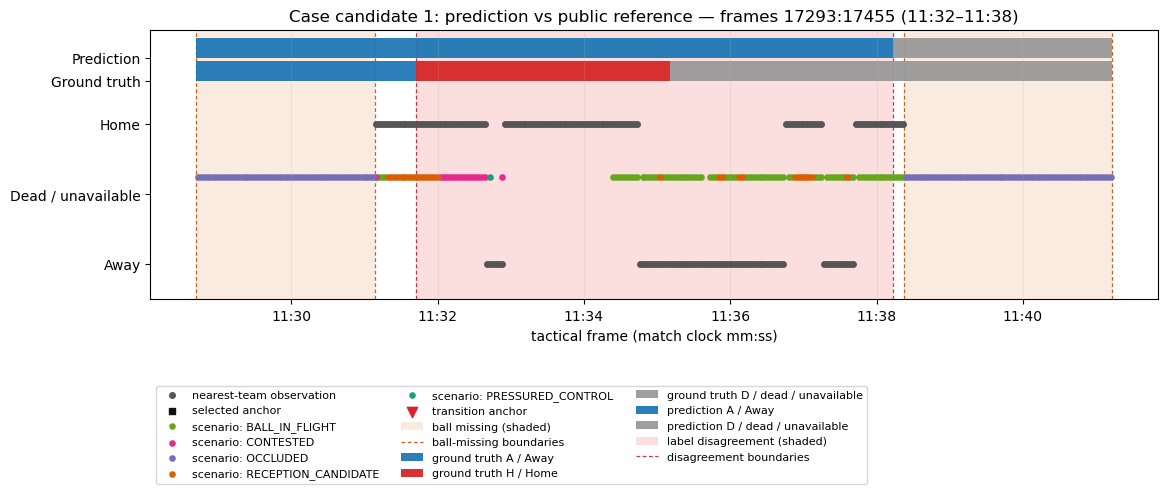

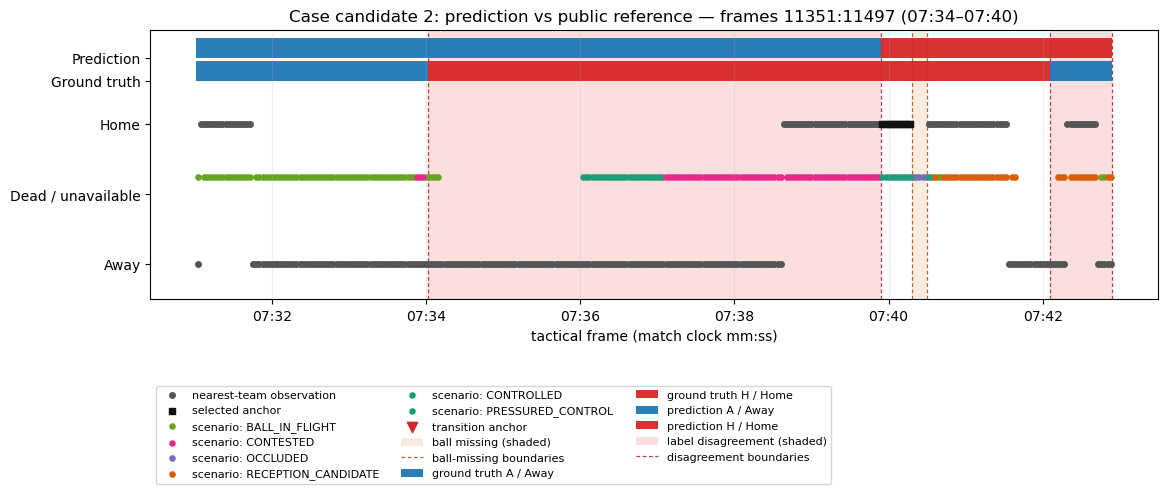

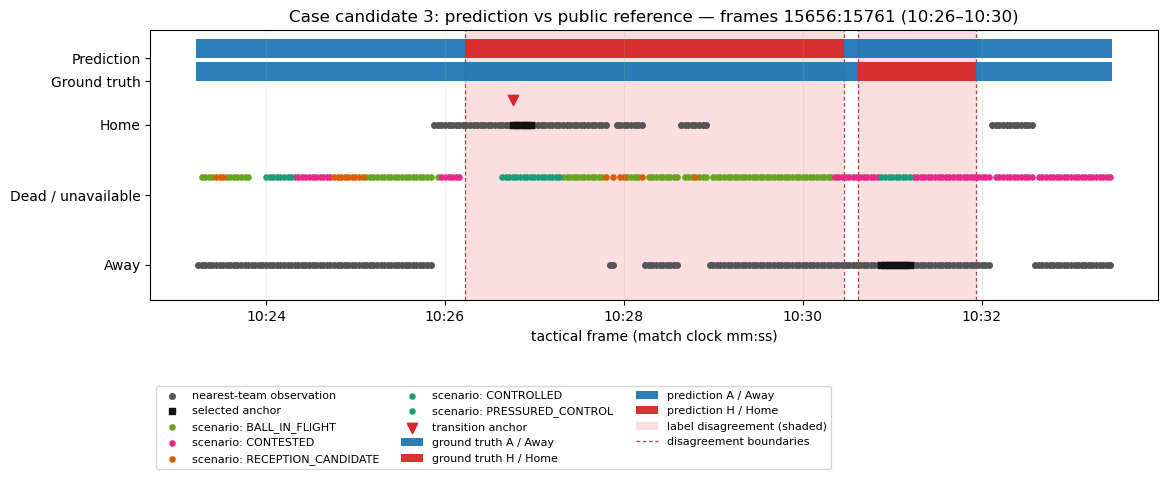

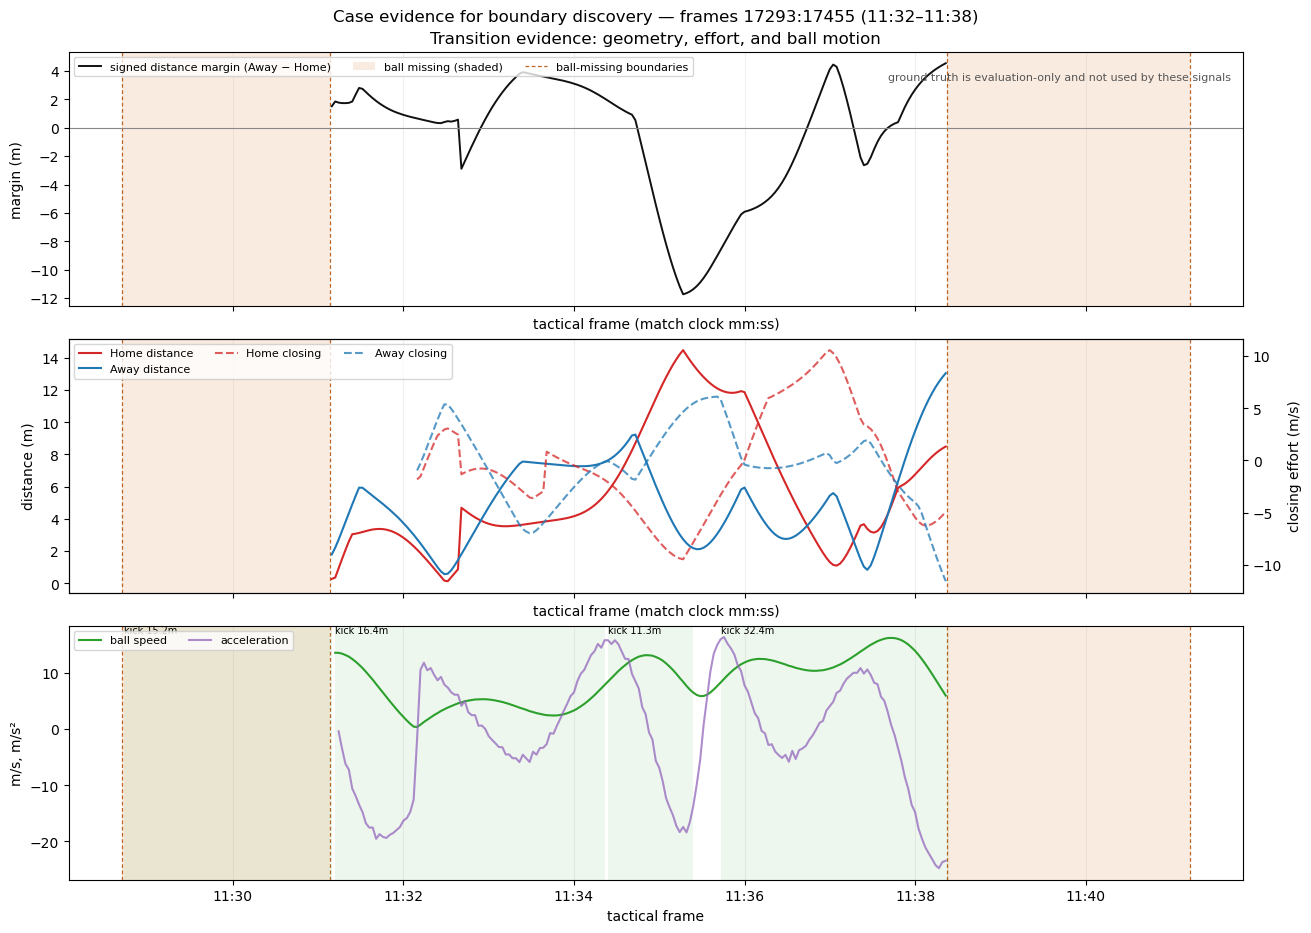

In [3]:
from possession_lab.calculations.plotting import plot_timeline_window, format_match_clock, plot_transition_signals_window

def _clock_range(table, start_frame, end_frame):
    frame = pd.to_numeric(table['frame'], errors='coerce').to_numpy(float)
    clock = pd.to_numeric(table.get('match_clock_s', table['frame'] / 25.0), errors='coerce').to_numpy(float)
    valid = np.isfinite(frame) & np.isfinite(clock)
    if valid.sum() < 2:
        return '--:--–--:--'
    return f'{format_match_clock(np.interp(start_frame, frame[valid], clock[valid]))}–{format_match_clock(np.interp(end_frame, frame[valid], clock[valid]))}'

def _has_dead_label(row):
    frames = np.arange(int(row.start_frame), int(row.end_frame) + 1)
    return bool((gt_by_frame.reindex(frames).eq('D') | pred_by_frame.reindex(frames).eq('D')).any())

dead_cases = window_table[window_table.apply(_has_dead_label, axis=1)] if len(window_table) else window_table
selected_cases = pd.concat([dead_cases.head(1), window_table.head(3)], ignore_index=True).drop_duplicates(['start_frame', 'end_frame']).head(3)
context_frames = 75
for number, row in enumerate(selected_cases.itertuples(index=False), start=1):
    left = max(int(plot_features['frame'].min()), int(row.start_frame) - context_frames)
    right = min(int(plot_features['frame'].max()), int(row.end_frame) + context_frames)
    figure, axis = plot_timeline_window(plot_features, left, right, ground_truth=gt_by_frame, predicted_labels=pred_by_frame)
    clock = _clock_range(plot_features, int(row.start_frame), int(row.end_frame))
    axis.set_title(f'Case candidate {number}: prediction vs public reference — frames {int(row.start_frame)}:{int(row.end_frame)} ({clock})')
    plt.show()

if len(selected_cases):
    row = selected_cases.iloc[0]
    left = max(int(plot_features['frame'].min()), int(row.start_frame) - context_frames)
    right = min(int(plot_features['frame'].max()), int(row.end_frame) + context_frames)
    figure, axes = plot_transition_signals_window(plot_features, left, right, ground_truth=gt_by_frame)
    figure.suptitle(f'Case evidence for boundary discovery — frames {int(row.start_frame)}:{int(row.end_frame)} ({_clock_range(plot_features, int(row.start_frame), int(row.end_frame))})', y=1.02)
    plt.show()

## What a disagreement means

A disagreement is not a label to copy. It is a prompt to ask which signal is absent: contact, receiver arrival, pressure, path direction, restart activation, persistent control, or a genuine dead-ball onset. The resolver keeps these questions separate: a contact anchor says that something happened; a switch hypothesis asks whether ownership changed; a control anchor confirms sustained ownership; restart activation says that play is live again.

This is why the pipeline can remain conservative without ignoring small transitions. It uses backward and forward context to open a bounded hypothesis interval, retains `CONTESTED` when two teams remain plausible, and changes `D` only when a dead-ball hypothesis is supported by forward settling and then released by restart or control evidence.

## Missing-ball audit

The source-gap audit separates visible-ball errors from missing-ball errors. This matters for the private full match, where gaps are common, but it prevents us from claiming that every public disagreement was caused by a missing ball.

In [4]:
from possession_lab.mislabel_audit import build_missing_ball_disagreement_audit

missing_ball_audit = build_missing_ball_disagreement_audit(
    GROUND_TRUTH,
    BEST_OUTPUT,
    plot_features,
    ROOT / 'evaluation' / 'reports' / 'missing_ball_disagreement_summary.csv',
)
display(missing_ball_audit['summary'])
display(missing_ball_audit['by_error'])

,population,frames,disagreement_frames,disagreement_rate,fraction_of_all_disagreements
0,all_graded,7500,804,0.107200,1.000000
1,ball_visible_graded,6615,784,0.118519,0.975124
2,ball_missing_graded,885,20,0.022599,0.024876
3,george_observed_gap_graded,0,0,NaN,0.000000


,error_type,ball_missing_source_gap,frames
5,H_TO_A,False,351
2,A_TO_H,False,216
3,D_TO_A,False,162
0,A_TO_D,False,33
4,D_TO_H,False,22
1,A_TO_D,True,20


## Takeaway

The promoted output is produced by [08_run_pipeline.ipynb](08_run_pipeline.ipynb). This notebook supplies a small, visual error-analysis argument for why the full-match system needs local contact/arrival evidence, explicit dead-ball boundaries, and missing-ball uncertainty. Optional learned or alternate-observation experiments remain separate audit material in [appendix/09_experimental_results.ipynb](appendix/09_experimental_results.ipynb); they do not replace the promoted labels.